# Bloque 2: CNN Propia Base en Escala de Grises
En este cuaderno implementamos el modelo baseline de arquitectura propia. Las radiografías se redimensionan a (224, 224) y se procesan en escala de grises.

In [1]:
!pip install numpy
!pip install opencv-python
!pip install scikit-learn
!pip install matplotlib
!pip install tensorflow
!pip install keras-tuner
!pip install kaggle

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [keras-tuner]


In [3]:
#@title 1. Montar Drive y cargar datos
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

RUTA_PROYECTO = '/content/drive/MyDrive/Proyecto-neumonia'
os.chdir(RUTA_PROYECTO)
print(f"Directorio de trabajo: {os.getcwd()}")

# Cargar los .npy
X_train = np.load('X_train.npy')
y_train = np.load('y_train.npy')
X_val = np.load('X_val.npy')
y_val = np.load('y_val.npy')
X_test = np.load('X_test.npy')
y_test = np.load('y_test.npy')

print(f"Resumen de dimensiones:")
print(f"  X_train: {X_train.shape} | Rango: [{X_train.min():.2f}, {X_train.max():.2f}]")
print(f"  X_val:   {X_val.shape}")
print(f"  X_test:  {X_test.shape}")

Directorio de trabajo: /content/drive/MyDrive/Proyecto-neumonia
Resumen de dimensiones:
  X_train: (4000, 180, 180, 1) | Rango: [0.00, 1.00]
  X_val:   (400, 180, 180, 1)
  X_test:  (2100, 180, 180, 1)


In [6]:
#@title 2. Definir la CNN Base (tu arquitectura)
SEED = 230406
tf.keras.utils.set_random_seed(SEED)

BATCH_SIZE = 32
IMG_SHAPE = (180, 180, 1)
EPOCHS = 6

def build_baseline_cnn():
    """Arquitectura CNN base en escala de grises (180, 180, 1)"""
    model = Sequential([
        Conv2D(32, (3, 3), activation='relu', input_shape=IMG_SHAPE),
        MaxPooling2D(2, 2),
        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D(2, 2),
        Flatten(),
        Dense(128, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=[
            'accuracy',
            tf.keras.metrics.AUC(name='auc'),
            tf.keras.metrics.Precision(name='precision'),
            tf.keras.metrics.Recall(name='recall')
        ]
    )
    return model

model_base = build_baseline_cnn()
model_base.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 178, 178, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 118336)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    15,147,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,166,081 (57.85 MB)

 Trainable params: 15,166,081 (57.85 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
#@title 3. Entrenamiento del Modelo Base (Sin Data Augmentation)
print("=" * 70)
print("ENTRENANDO MODELO BASE (SIN DATA AUGMENTATION)")
print("=" * 70)

historial_base = model_base.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val),
    verbose=1
)

# Guardar el modelo
model_base.save('modelo_base_sin_da.keras')
print("\nModelo guardado en: modelo_base_sin_da.keras")

ENTRENANDO MODELO BASE (SIN DATA AUGMENTATION)
Epoch 1/6
125/125 ━━━━━━━━━━━━━━━━━━━━ 242s 2s/step - accuracy: 0.8860 - auc: 0.9517 - loss: 0.3189 - precision: 0.8868 - recall: 0.8850 - val_accuracy: 0.9450 - val_auc: 0.9824 - val_loss: 0.1541 - val_precision: 0.9588 - val_recall: 0.9300
Epoch 2/6
125/125 ━━━━━━━━━━━━━━━━━━━━ 231s 2s/step - accuracy: 0.9480 - auc: 0.9887 - loss: 0.1340 - precision: 0.9462 - recall: 0.9500 - val_accuracy: 0.9350 - val_auc: 0.9881 - val_loss: 0.1535 - val_precision: 0.9028 - val_recall: 0.9750
Epoch 3/6
125/125 ━━━━━━━━━━━━━━━━━━━━ 236s 2s/step - accuracy: 0.9628 - auc: 0.9934 - loss: 0.1015 - precision: 0.9630 - recall: 0.9625 - val_accuracy: 0.9275 - val_auc: 0.9913 - val_loss: 0.1690 - val_precision: 0.8800 - val_recall: 0.9900
Epoch 4/6
125/125 ━━━━━━━━━━━━━━━━━━━━ 241s 2s/step - accuracy: 0.9680 - auc: 0.9954 - loss: 0.0828 - precision: 0.9675 - recall: 0.9685 - val_accuracy: 0.9250 - val_auc: 0.9906 - val_loss: 0.1888 - val_precision: 0.8761 - val_

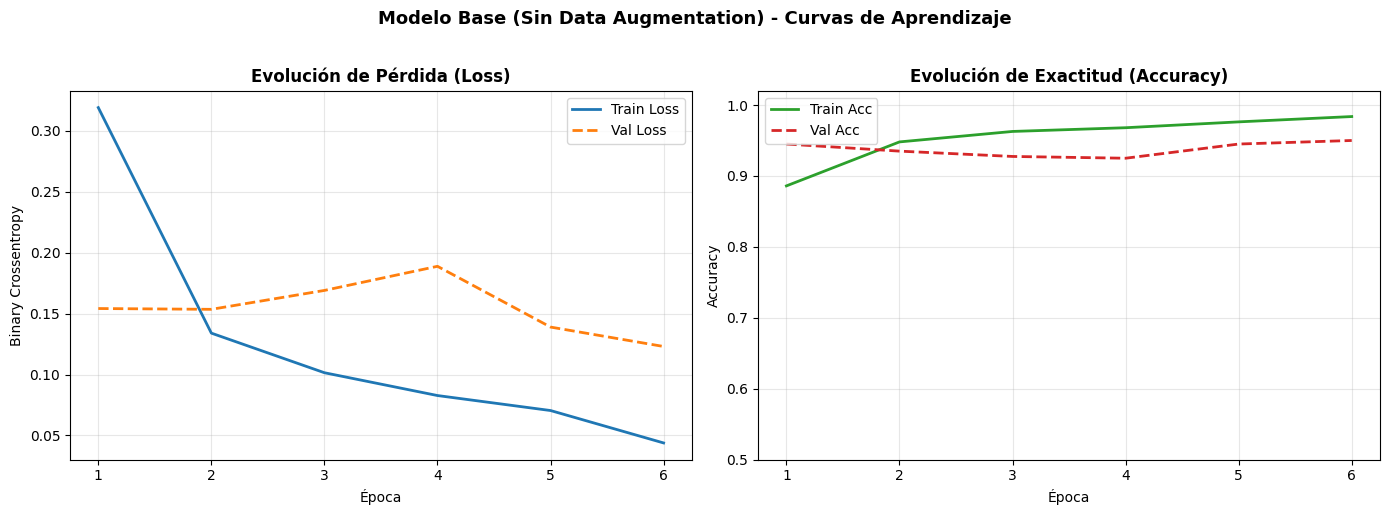

Brecha Overfitting (última época):
  Accuracy: Train 0.9837 | Val 0.9500 | Gap 0.0337
  Loss:     Train 0.0439 | Val 0.1230 | Gap 0.0791


In [8]:
#@title 4. Curvas de Aprendizaje (Pérdida y Exactitud)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
h = historial_base.history
epocas = range(1, len(h['loss']) + 1)

# Pérdida
axes[0].plot(epocas, h['loss'], label='Train Loss', lw=2, color='tab:blue')
axes[0].plot(epocas, h['val_loss'], label='Val Loss', lw=2, linestyle='--', color='tab:orange')
axes[0].set_title("Evolución de Pérdida (Loss)", fontweight='bold')
axes[0].set_ylabel("Binary Crossentropy")
axes[0].set_xlabel("Época")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Exactitud
axes[1].plot(epocas, h['accuracy'], label='Train Acc', lw=2, color='tab:green')
axes[1].plot(epocas, h['val_accuracy'], label='Val Acc', lw=2, linestyle='--', color='tab:red')
axes[1].set_title("Evolución de Exactitud (Accuracy)", fontweight='bold')
axes[1].set_ylabel("Accuracy")
axes[1].set_xlabel("Época")
axes[1].set_ylim(0.5, 1.02)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.suptitle("Modelo Base (Sin Data Augmentation) - Curvas de Aprendizaje",
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Brecha de overfitting
gap_acc = h['accuracy'][-1] - h['val_accuracy'][-1]
gap_loss = h['val_loss'][-1] - h['loss'][-1]
print(f"Brecha Overfitting (última época):")
print(f"  Accuracy: Train {h['accuracy'][-1]:.4f} | Val {h['val_accuracy'][-1]:.4f} | Gap {gap_acc:.4f}")
print(f"  Loss:     Train {h['loss'][-1]:.4f} | Val {h['val_loss'][-1]:.4f} | Gap {gap_loss:.4f}")

In [9]:
#@title 5. Evaluación en X_test - Métricas Clínicas (Priorizando Sensibilidad)
y_prob = model_base.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)  # Sensibilidad clínica
spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_prob)

resultados = {
    'Modelo': 'Base (Sin DA)',
    'Accuracy': round(acc, 4),
    'Precision': round(prec, 4),
    'Recall (Sensibilidad)': round(rec, 4),
    'Especificidad': round(spec, 4),
    'F1-Score': round(f1, 4),
    'AUC-ROC': round(auc, 4),
    'Falsos Negativos (FN)': int(fn),
    'Falsos Positivos (FP)': int(fp),
    'Brecha Overfitting (Train-Val Acc)': round(gap_acc, 4)
}

df_resultados = pd.DataFrame([resultados])
display(df_resultados)

print("\nReporte de clasificación detallado:")
print(f"{'':>20} {'precision':>10} {'recall':>10} {'f1-score':>10} {'support':>10}")
print(f"{'No Neumonía (0)':>20} {tn/(tn+fn) if (tn+fn)>0 else 0:>10.4f} {tn/(tn+fp) if (tn+fp)>0 else 0:>10.4f} {2*tn/(2*tn+fp+fn) if (2*tn+fp+fn)>0 else 0:>10.4f} {tn+fn:>10}")
print(f"{'Neumonía (1)':>20} {tp/(tp+fp) if (tp+fp)>0 else 0:>10.4f} {tp/(tp+fn) if (tp+fn)>0 else 0:>10.4f} {2*tp/(2*tp+fp+fn) if (2*tp+fp+fn)>0 else 0:>10.4f} {tp+fn:>10}")
print(f"{'accuracy':>20} {'':>10} {'':>10} {acc:>10.4f} {tn+fp+fn+tp:>10}")

,Modelo,Accuracy,Precision,Recall (Sensibilidad),Especificidad,F1-Score,AUC-ROC,Falsos Negativos (FN),Falsos Positivos (FP),Brecha Overfitting (Train-Val Acc)
0,Base (Sin DA),0.959,0.9406,0.98,0.9381,0.9599,0.9887,21,65,0.0337



Reporte de clasificación detallado:
                      precision     recall   f1-score    support
     No Neumonía (0)     0.9791     0.9381     0.9582       1006
        Neumonía (1)     0.9406     0.9800     0.9599       1050
            accuracy                           0.9590       2100


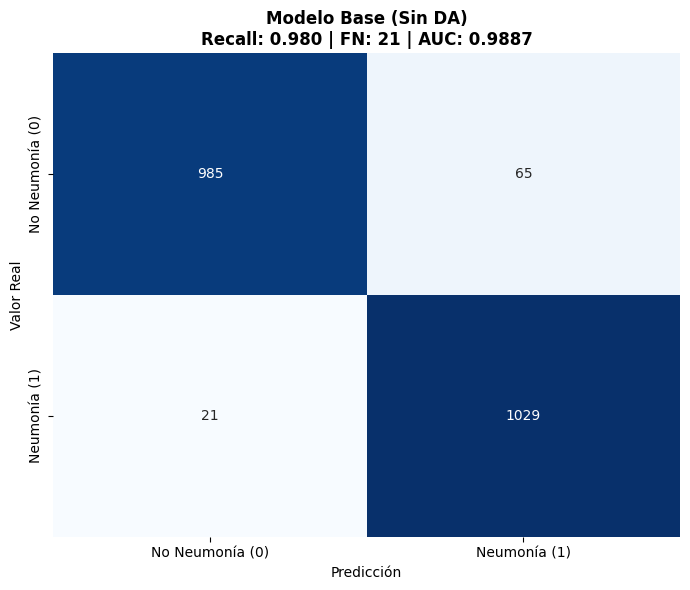

In [10]:
#@title 6. Matriz de Confusión
fig, ax = plt.subplots(1, 1, figsize=(7, 6))

cm = np.array([[tn, fp], [fn, tp]])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['No Neumonía (0)', 'Neumonía (1)'],
            yticklabels=['No Neumonía (0)', 'Neumonía (1)'])
ax.set_title(f"Modelo Base (Sin DA)\nRecall: {rec:.3f} | FN: {fn} | AUC: {auc:.4f}",
             fontweight='bold')
ax.set_xlabel('Predicción')
ax.set_ylabel('Valor Real')
plt.tight_layout()
plt.show()

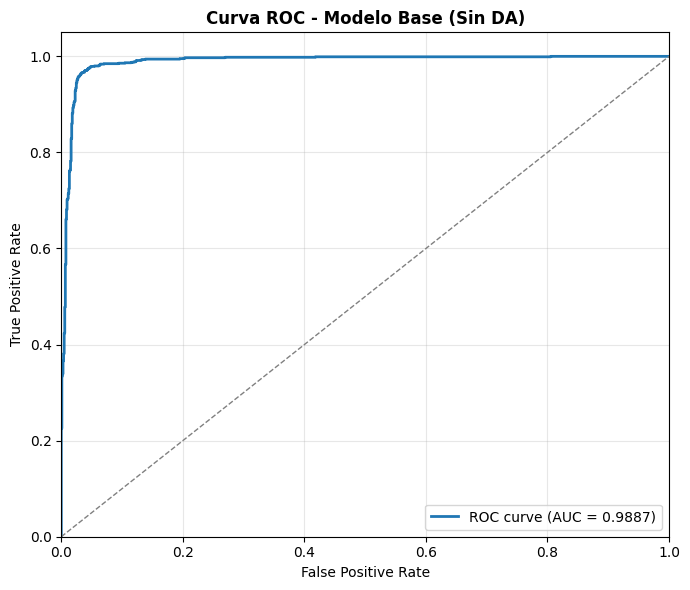

In [11]:
#@title 7. Curva ROC
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

fig, ax = plt.subplots(1, 1, figsize=(7, 6))
ax.plot(fpr, tpr, color='tab:blue', lw=2, label=f'ROC curve (AUC = {auc:.4f})')
ax.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('Curva ROC - Modelo Base (Sin DA)', fontweight='bold')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
#@title 8. Resumen Final
print("=" * 70)
print("RESUMEN - MODELO BASE (SIN DATA AUGMENTATION)")
print("=" * 70)
print(f"  Accuracy:              {acc:.4f}")
print(f"  Precision:             {prec:.4f}")
print(f"  Recall (Sensibilidad): {rec:.4f}")
print(f"  Especificidad:         {spec:.4f}")
print(f"  F1-Score:              {f1:.4f}")
print(f"  AUC-ROC:               {auc:.4f}")
print(f"  Falsos Negativos:      {fn}")
print(f"  Falsos Positivos:      {fp}")
print(f"  Brecha Overfitting:    {gap_acc:.4f}")
print("=" * 70)

RESUMEN - MODELO BASE (SIN DATA AUGMENTATION)
  Accuracy:              0.9590
  Precision:             0.9406
  Recall (Sensibilidad): 0.9800
  Especificidad:         0.9381
  F1-Score:              0.9599
  AUC-ROC:               0.9887
  Falsos Negativos:      21
  Falsos Positivos:      65
  Brecha Overfitting:    0.0337
